# 06 · Final compact-feature selection and model retuning

This is a **new development experiment**, after the exploratory appendices in notebook 02. It compares Logistic Regression, KNN, RBF SVM and Random Forest, using only 2025 for choices. January–June 2026 have already been evaluated; **July 2026 is reserved for notebook 07**.

We compare the existing 66 predictors with six pressure/wind features, six nonlinear weather features, and their combination (78 predictors). The goal is measured improvement, not a promised high score. No correlation cutoff is used.

**Primary selection metric: delayed-class F1 on later validation months.** Average precision breaks ties. This explicitly supersedes the earlier AP-first selection rule for this new round only; earlier benchmark decisions remain unchanged. All four models share flight IDs. Natural class prevalence is retained.

In [1]:
from pathlib import Path
import sys, json
from datetime import datetime, timezone
from time import perf_counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if (ROOT/'departure-delay-classification/config/project.json').exists(): ROOT /= 'departure-delay-classification'
sys.path.insert(0,str(ROOT/'scripts'))
from final_features import compact_columns, build_development, PRESSURE, SHAPES
from final_modelling import (MODELS, NAMES, FOLDS, GRID, sha, save, fingerprint,
    make_cohorts, fit, scores, threshold, metrics)
from baseline_integrity import verify_baseline_files
CONFIG = json.loads((ROOT/'config/project.json').read_text())
OLD = json.loads((ROOT/'reports/improvements/selection.json').read_text())
OUT = ROOT/'reports/final_models'
OUT.mkdir(exist_ok=True)
if (OUT/'test_access.json').exists():
    raise RuntimeError('July has been accessed. Preserve this frozen round; do not retune it.')
PROTECTED = json.loads((ROOT/'reports/improvements/baseline_fingerprints.json').read_text())
print(verify_baseline_files(ROOT,PROTECTED))
COLUMNS = compact_columns(ROOT)
COVERED = CONFIG['preprocessing']['explicit_missingness_covered_columns']
ANCHORS = {c['model_id']:c for c in OLD['choices'] if c['feature_set']=='B'}
RUN_ID = datetime.now(timezone.utc).strftime('final_%Y%m%dT%H%M%S%fZ')
sns.set_theme(style='whitegrid',palette=['#247BA0','#E08D3C','#5C946E','#8465A0'])
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def table(x,**kw): print(x.to_string(**kw))
def plot(): plt.tight_layout(); plt.show()
print('Run:',RUN_ID)
table(pd.Series({p:version(p) for p in ['numpy','pandas','scikit-learn','pyarrow','matplotlib','seaborn','joblib']},name='version'))

{'checked_files': 21, 'documented_notebook_appendices': {'notebooks/02_feature_engineering.ipynb': {'original_cells_preserved': 38, 'original_metadata_preserved': True}}}
Run: final_20261019T055940573924Z
numpy            2.5.1
pandas           3.0.3
scikit-learn     1.9.0
pyarrow         20.0.0
matplotlib      3.11.1
seaborn         0.13.2
joblib           1.5.3


## Declare the comparison before fitting

1. Screen all four feature packages with the earlier B settings (20,000 shared fitting flights per fold).
2. For each model, retune the current 66 features and its strongest additional package using the **same four-setting search**. This is a bounded two-stage search, not an exhaustive search of every feature/setting combination.
3. Select each model's feature/settings combination by mean F1 across the three scoring blocks; select the overall classifier by the same rule. Tie: AP, then fewer predictors, then lower search index.
4. Assess the fixed choices using 40,000 training flights on the latest fold. This check does **not** change the chosen model or settings. Choose warning thresholds on October; score November–December without refitting.
5. Refit on the shared 40,000 flights covering all twelve months of 2025. Carry the October thresholds forward, then freeze the bundle before July outcomes are loaded.

**Threshold limitation:** a threshold learned from a January–September fit can shift after refitting on all twelve months. Matching the 40,000 fitting size reduces one difference; it cannot remove seasonal or score-distribution changes. July will measure this transfer honestly. Scores are uncalibrated risk scores.

For O2, fit a schedule-only A control with each selected B model's exact settings and the same IDs. A includes the same time harmonics. A/B therefore measures added weather/history/traffic information at matched settings; it does not claim an independently optimized A model.

**Where sampling happens:** `scripts/final_modelling.py` → `sample()` / `make_cohorts()`, called in the next data cell. Exact IDs are saved in `reports/final_models/cohorts.json`; all eligible rows remain in the original Parquet handoffs.

In [2]:
PROTOCOL = {'run_id':RUN_ID,'declared_at_utc':datetime.now(timezone.utc).isoformat(),
    'development_period':'2025 only','fresh_test':'July 2026; 10000 shared flights; seed 42',
    'folds':FOLDS,'feature_packages':COLUMNS,'grid':GRID,
    'anchors':{m:{'recipe':v['recipe'],'params':v['params']} for m,v in ANCHORS.items()},
    'screening':'all four packages at prior B anchor settings, then equal four-setting searches on current_66 and strongest additional package per model',
    'selection':'unweighted mean scoring-block F1; AP tie-break; then fewer predictors and earlier search index',
    'threshold':'first validation month max F1; subsequent two months score without refit; largest threshold breaks ties',
    'sample':'shared proportional month x outcome; train20k; latest-fold train40k; final40k all2025; natural prevalence',
    'latest_40k_check':'assessment and October threshold estimation only; no model/feature reselection',
    'A_control':'same settings/recipe as selected B, same training/calibration/test IDs',
    'test_policy':'no July outcome access until settings, thresholds and refitted models are frozen',
    'threshold_transfer':'October threshold from 40k Jan-Sep fit transferred to 40k all2025 refit; not guaranteed invariant',
    'availability':'historical simulation; weather buffer20m/maxage180m; outcome history28d/lag7d; schedule snapshots assumed',
    'input_sha256':{p:sha(ROOT/p) for p in ['data/processed/features.parquet',
        'data/processed/flights_clean.parquet','reports/preparation_manifest.json',
        'scripts/improvement_features.py','scripts/final_features.py','scripts/final_modelling.py']}}
save(OUT/'protocol.json',PROTOCOL)
PROTOCOL_SHA = sha(OUT/'protocol.json')
table(pd.Series({k:len(v) for k,v in COLUMNS.items()},name='predictors'))

current_66           66
pressure_wind        72
nonlinear_weather    72
combined             78
A                    26


In [3]:
cohorts, final_ids, needed = make_cohorts(ROOT)
save(OUT/'cohorts.json',{'folds':cohorts,'final_refit_ids':final_ids})
working, weather_audit = build_development(ROOT,needed,CONFIG['weather_quality']['excluded_station_times'])
assert working['flight_date'].between('2025-01-01','2025-12-31').all()
assert len(working)==len(needed)
cohort_table = pd.DataFrame([{'scoring_block':name,**{role:len(ids) for role,ids in c.items()},
    'scoring_delay_rate':working.loc[c['score'],'delayed_departure'].mean()} for name,c in cohorts.items()])
table(cohort_table,index=False)
print('2025 development flights in memory:',len(working))
print('Final fit month coverage:',working.loc[final_ids,'flight_date'].dt.month.nunique())

scoring_block  train20  train40  calibrate  score  scoring_delay_rate
      May–Jun    20000    40000       1574   3426            0.298891
      Aug–Sep    20000    40000       1729   3271            0.232956
      Nov–Dec    20000    40000       1781   3219            0.273687
2025 development flights in memory: 149379
Final fit month coverage: 12


## Inspect the compact additions

Pressure is altimeter setting parsed from the METAR body, not sea-level pressure. Rolling changes use only reports at or before the matched, buffered observation. Unknown gusts stay unknown. All numeric imputation and scaling are learned separately inside each fitting pipeline.

                             missing_fraction  unique_nonmissing
altimeter_inhg                       0.000000                165
altimeter_change3h_inhg              0.000000                 81
altimeter_range3h_inhg               0.000000                 43
variable_wind_flag                   0.000221                  2
gust_excess_knots                    0.786456                 30
altimeter_missing_flag               0.000000                  1
temperature_centered_square          0.000000                104
wind_square                          0.000214                 35
dewpoint_spread_square               0.000000                 90
precip_log1p                         0.000000                 74
ceiling_log1p                        0.463606                 77
visibility_inverse                   0.000000                 19


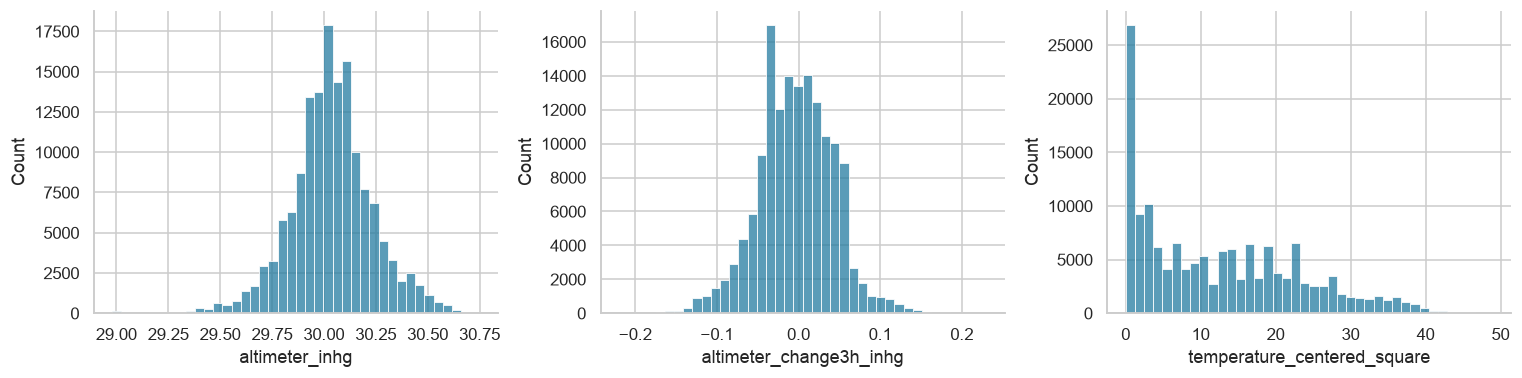

In [4]:
profile = pd.DataFrame({'missing_fraction':working[PRESSURE+SHAPES].isna().mean(),
    'unique_nonmissing':working[PRESSURE+SHAPES].nunique()})
table(profile)
fig,axes = plt.subplots(1,3,figsize=(14,3.6))
for c,ax in zip(['altimeter_inhg','altimeter_change3h_inhg','temperature_centered_square'],axes):
    sns.histplot(data=working,x=c,bins=40,ax=ax)
plot()

## Evaluate without mixing calibration and scoring

April, July and October 2025 choose thresholds. May–June, August–September and November–December measure performance. Feature screening and tuning reuse these development blocks, so their results are optimistic selection evidence, not final-test estimates. No SMOTE, balanced evaluation data, aircraft assignments or post-cutoff outcomes enter the predictors.

In [5]:
runs, audit_arrays = [], {}
def evaluate(model_id,package,params,recipe=None,size=20000,fold_names=None,stage='tuning'):
    recipe = recipe or ANCHORS[model_id]['recipe']
    token = json.dumps([model_id,package,recipe,params,size,fold_names],sort_keys=True)
    existing = next((r for r in runs if r['token']==token),None)
    if existing: return existing
    columns = COLUMNS[package]
    key = 'r'+str(len(runs))
    rows = []
    for fold,c in cohorts.items():
        if fold_names and fold not in fold_names: continue
        train,calibration,scoring = [working.loc[c[role]] for role in [
            'train20' if size==20000 else 'train40','calibrate','score']]
        model,elapsed = fit(model_id,columns,recipe,params,COVERED,train)
        started = perf_counter()
        cal_s,s = scores(model,calibration[columns]),scores(model,scoring[columns])
        prediction_seconds = perf_counter()-started
        assert np.isfinite(cal_s).all() and np.isfinite(s).all()
        t = threshold(calibration['delayed_departure'],cal_s)
        y = scoring['delayed_departure'].to_numpy(dtype=int)
        rows.append(dict(fold=fold,threshold=t,fit_seconds=elapsed,prediction_seconds=prediction_seconds,
            calibration_n=len(calibration),**metrics(y,s,t)))
        audit_arrays[key+'_'+fold+'_score'] = s
        audit_arrays[key+'_'+fold+'_calibration'] = cal_s
        print(f'{model_id}/{package}/{size:,}/{fold}: F1={rows[-1]["f1"]:.4f}, AP={rows[-1]["average_precision"]:.4f}',flush=True)
    row = dict(key=key,token=token,model_id=model_id,package=package,params=params,recipe=recipe,
        size=size,stage=stage,folds=rows,mean_f1=float(np.mean([r['f1'] for r in rows])),
        mean_ap=float(np.mean([r['average_precision'] for r in rows])),
        mean_precision=float(np.mean([r['precision'] for r in rows])),
        mean_recall=float(np.mean([r['recall'] for r in rows])),
        mean_fit_seconds=float(np.mean([r['fit_seconds'] for r in rows])))
    runs.append(row)
    save(OUT/'development.json',{'status':'running','run_id':RUN_ID,'runs':runs})
    return row

def best(rows):
    return sorted(rows,key=lambda r:(-r['mean_f1'],-r['mean_ap'],len(COLUMNS[r['package']]),runs.index(r)))[0]

BROAD_REFERENCE = json.loads((ROOT/'reports/broad_feature_experiments.json').read_text())['runs']
for model_id in MODELS:
    for package in list(COLUMNS)[:4]:
        r = evaluate(model_id,package,ANCHORS[model_id]['params'],stage='feature_screen')
        if package!='combined':
            for fold in r['folds']:
                old = next(x for x in BROAD_REFERENCE if x['model_id']==model_id and x['package']==package and x['fold']==fold['fold'])
                np.testing.assert_allclose([fold['f1'],fold['average_precision']],
                    [old['f1'],old['average_precision']],rtol=0,atol=1e-12)

logistic_regression/current_66/20,000/May–Jun: F1=0.4995, AP=0.4546


logistic_regression/current_66/20,000/Aug–Sep: F1=0.4353, AP=0.4025


logistic_regression/current_66/20,000/Nov–Dec: F1=0.4807, AP=0.4429


logistic_regression/pressure_wind/20,000/May–Jun: F1=0.4947, AP=0.4529


logistic_regression/pressure_wind/20,000/Aug–Sep: F1=0.4397, AP=0.4044


...

random_forest/nonlinear_weather/20,000/Aug–Sep: F1=0.4522, AP=0.3963


random_forest/nonlinear_weather/20,000/Nov–Dec: F1=0.4690, AP=0.4312


random_forest/combined/20,000/May–Jun: F1=0.4976, AP=0.4736


random_forest/combined/20,000/Aug–Sep: F1=0.4520, AP=0.4056


random_forest/combined/20,000/Nov–Dec: F1=0.4715, AP=0.4301


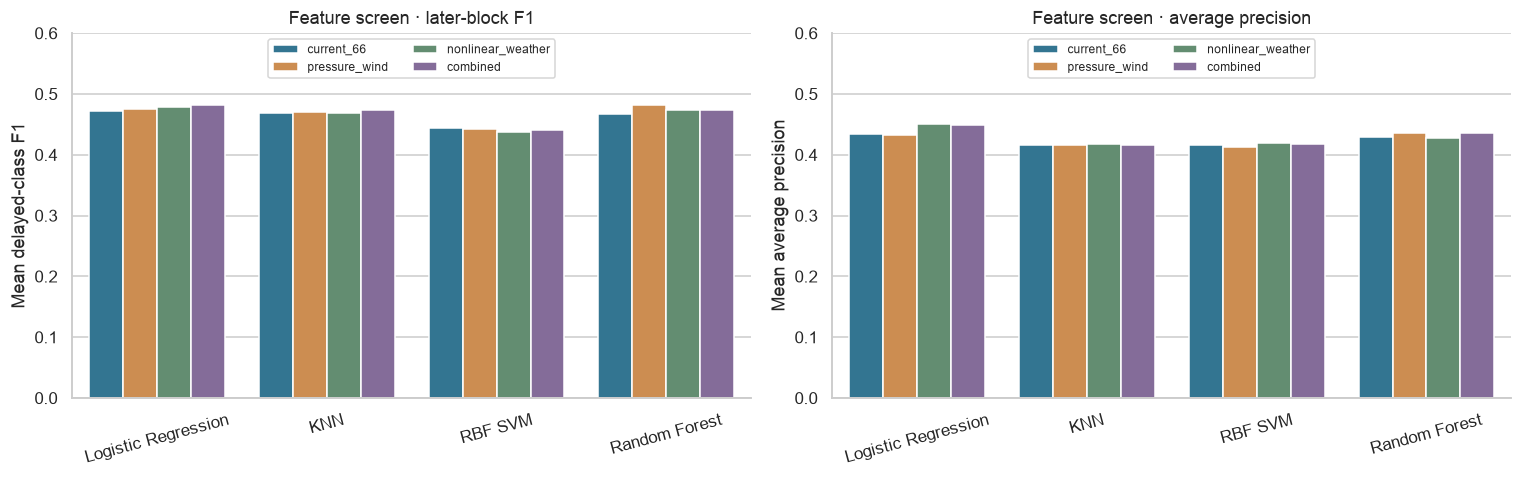

In [6]:
screen = pd.DataFrame([{k:r[k] for k in ['model_id','package','mean_f1','mean_ap']} for r in runs if r['stage']=='feature_screen'])
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
sns.barplot(data=screen,x='model_id',y='mean_f1',hue='package',ax=axes[0])
sns.barplot(data=screen,x='model_id',y='mean_ap',hue='package',ax=axes[1])
for ax in axes:
    ax.set_ylim(0,.6)
    ax.set_xlabel('')
    ax.set_xticks(ax.get_xticks(),['Logistic Regression','KNN','RBF SVM','Random Forest'],rotation=15)
    ax.legend(loc='upper center',ncol=2,fontsize=8)
axes[0].set(title='Feature screen · later-block F1',ylabel='Mean delayed-class F1')
axes[1].set(title='Feature screen · average precision',ylabel='Mean average precision')
plot()

In [7]:
shortlists = {}
for model_id in MODELS:
    extra = best([r for r in runs if r['model_id']==model_id and r['package'] not in ['current_66','A']])['package']
    shortlists[model_id] = ['current_66',extra]
    for package in shortlists[model_id]:
        for params in GRID[model_id]:
            evaluate(model_id,package,params)
selected_by_model, reference_by_model = {},{}
for model_id in MODELS:
    candidates = [r for r in runs if r['model_id']==model_id and r['size']==20000]
    selected_by_model[model_id] = best(candidates)
    reference_by_model[model_id] = best([r for r in candidates if r['package']=='current_66'])
chosen = best(list(selected_by_model.values()))
selection_table = pd.DataFrame([{'model':NAMES[m],'package':r['package'],'F1':r['mean_f1'],
    'AP':r['mean_ap'],'precision':r['mean_precision'],'recall':r['mean_recall'],
    'current66_retuned_F1':reference_by_model[m]['mean_f1'],'params':json.dumps(r['params'])}
    for m,r in selected_by_model.items()])
table(selection_table,index=False)
print('Validation-selected classifier:',NAMES[chosen['model_id']])

logistic_regression/current_66/20,000/May–Jun: F1=0.4785, AP=0.4530


logistic_regression/current_66/20,000/Aug–Sep: F1=0.4484, AP=0.4045


logistic_regression/current_66/20,000/Nov–Dec: F1=0.4832, AP=0.4424


logistic_regression/current_66/20,000/May–Jun: F1=0.4918, AP=0.4554


logistic_regression/current_66/20,000/Aug–Sep: F1=0.4201, AP=0.3984


...

random_forest/pressure_wind/20,000/Nov–Dec: F1=0.4678, AP=0.4311


random_forest/pressure_wind/20,000/May–Jun: F1=0.4868, AP=0.4676


random_forest/pressure_wind/20,000/Aug–Sep: F1=0.4535, AP=0.4094


random_forest/pressure_wind/20,000/Nov–Dec: F1=0.4763, AP=0.4251


              model       package       F1       AP  precision   recall  current66_retuned_F1                                                             params
Logistic Regression      combined 0.483484 0.449869   0.369030 0.701639              0.471847                                                        {"C": 0.01}
                KNN      combined 0.474153 0.416809   0.376225 0.644227              0.470718 {"n_neighbors": 101, "weights": "distance", "metric": "euclidean"}
            RBF SVM    current_66 0.447176 0.399481   0.332386 0.709060              0.447176                                       {"C": 3.0, "gamma": "scale"}
      Random Forest pressure_wind 0.481618 0.436196   0.383752 0.651181              0.475112                           {"max_depth": 16, "min_samples_leaf": 5}
Validation-selected classifier: Logistic Regression


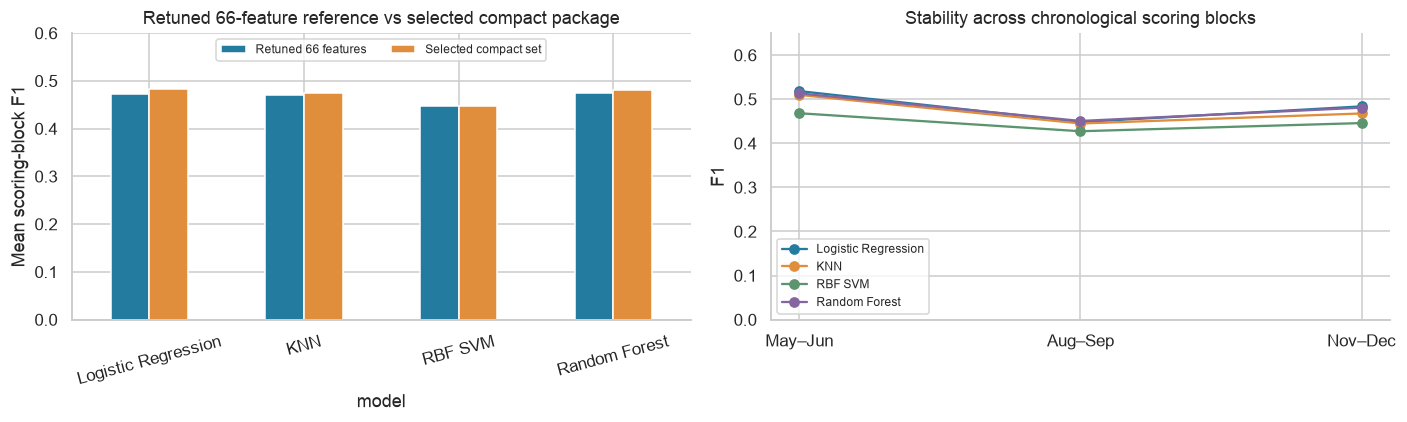

In [8]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
selection_table.set_index('model')[['current66_retuned_F1','F1']].rename(columns={'current66_retuned_F1':'Retuned 66 features','F1':'Selected compact set'}).plot.bar(ax=axes[0])
axes[0].set(ylabel='Mean scoring-block F1',title='Retuned 66-feature reference vs selected compact package',ylim=(0,.6))
for m,r in selected_by_model.items():
    axes[1].plot([x['fold'] for x in r['folds']],[x['f1'] for x in r['folds']],marker='o',label=NAMES[m])
axes[1].set(ylabel='F1',title='Stability across chronological scoring blocks',ylim=(0,.65))
axes[1].legend(fontsize=8)
axes[0].tick_params(axis='x',rotation=15)
axes[0].legend(loc='upper center',ncol=2,fontsize=8)
plot()

## Fixed-choice check at 40,000 flights

Model/feature selection is now complete. The latest chronological fold uses 40,000 fitting flights to match the approved final fitting size. Its October threshold is transferred to the all-2025 refit. November–December results below assess this larger fit but do not change the selection. A is an explicitly matched-settings schedule control.

In [9]:
large_checks, policies = {},{}
for m in MODELS:
    choice,reference = selected_by_model[m],reference_by_model[m]
    policies[m] = {}
    for label,r in [('B',choice),('reference66',reference),('A',choice)]:
        package = 'A' if label=='A' else r['package']
        check = evaluate(m,package,r['params'],recipe=r['recipe'],size=40000,fold_names=['Nov–Dec'],stage='fixed_40k_check')
        policies[m][label] = {'package':package,'params':r['params'],'recipe':r['recipe'],
            'threshold':check['folds'][0]['threshold'],'check_key':check['key']}
        large_checks[m+'__'+label] = check
large_table = pd.DataFrame([{'model':NAMES[m],'feature_set':label,
    **{k:r['folds'][0][k] for k in ['f1','average_precision','precision','recall','warnings','fit_seconds']}}
    for m in MODELS for label in ['A','reference66','B'] for r in [large_checks[m+'__'+label]]])
table(large_table,index=False)
np.savez_compressed(OUT/'development_scores.npz',**audit_arrays)
save(OUT/'development.json',{'status':'selection_complete','run_id':RUN_ID,'shortlists':shortlists,
    'selected_model_id':chosen['model_id'],'selected_by_model':selected_by_model,
    'reference_by_model':reference_by_model,'runs':runs})

logistic_regression/combined/40,000/Nov–Dec: F1=0.4870, AP=0.4535


logistic_regression/current_66/40,000/Nov–Dec: F1=0.4878, AP=0.4484


logistic_regression/A/40,000/Nov–Dec: F1=0.4623, AP=0.3990


knn/combined/40,000/Nov–Dec: F1=0.4634, AP=0.3923


knn/current_66/40,000/Nov–Dec: F1=0.4640, AP=0.3931


...

svm/A/40,000/Nov–Dec: F1=0.4298, AP=0.2976


random_forest/pressure_wind/40,000/Nov–Dec: F1=0.4700, AP=0.4394


random_forest/current_66/40,000/Nov–Dec: F1=0.4749, AP=0.4407


random_forest/A/40,000/Nov–Dec: F1=0.4473, AP=0.3810


              model feature_set       f1  average_precision  precision   recall  warnings  fit_seconds
Logistic Regression           A 0.462282           0.398956   0.343646 0.706016      1810     0.124438
Logistic Regression reference66 0.487843           0.448436   0.372678 0.706016      1669     0.358508
Logistic Regression           B 0.486978           0.453459   0.382965 0.668558      1538     0.385939
                KNN           A 0.448722           0.357498   0.305237 0.846765      2444     0.082838
                KNN reference66 0.464042           0.393132   0.325274 0.809308      2192     0.164039
                KNN           B 0.463388           0.392265   0.341202 0.721907      1864     0.191470
            RBF SVM           A 0.429756           0.297585   0.273687 1.000000      3219    57.884229
            RBF SVM reference66 0.441773           0.414880   0.330152 0.667423      1781   245.684524
            RBF SVM           B 0.441773           0.414880   0.330152 0.

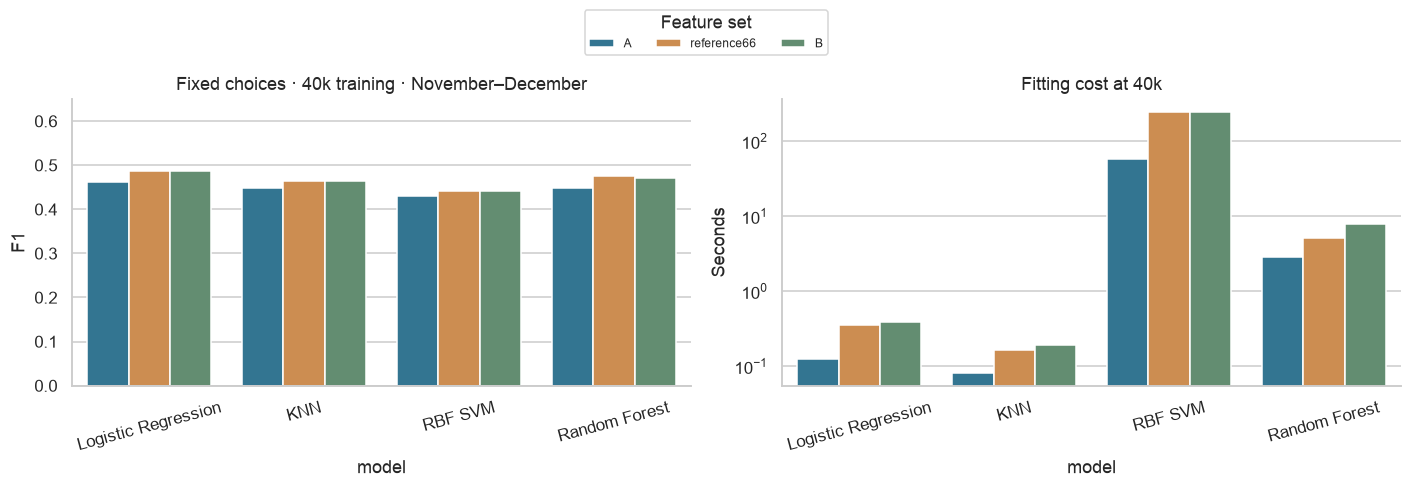

In [10]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=large_table,x='model',y='f1',hue='feature_set',hue_order=['A','reference66','B'],ax=axes[0])
sns.barplot(data=large_table,x='model',y='fit_seconds',hue='feature_set',hue_order=['A','reference66','B'],ax=axes[1])
axes[0].set(title='Fixed choices · 40k training · November–December',ylabel='F1',ylim=(0,.65))
axes[1].set(title='Fitting cost at 40k',ylabel='Seconds',yscale='log')
for ax in axes:
    ax.tick_params(axis='x',rotation=15)
    ax.get_legend().remove()
handles,labels = axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,1.12),ncol=3,title='Feature set',fontsize=8)
plot()

In [11]:
# Freeze settings and thresholds before the final refits, and before any July outcome access.
SELECTION = {'run_id':RUN_ID,'settings_frozen_at_utc':datetime.now(timezone.utc).isoformat(),
    'protocol_sha256':PROTOCOL_SHA,'development_sha256':sha(OUT/'development.json'),
    'selected_model_id':chosen['model_id'],'selected_feature_set':'B','selection_metric':'mean chronological delayed-class F1',
    'selected_by_model':selected_by_model,'policies':policies,
    'columns':COLUMNS,'refit_ids_sha256':fingerprint(final_ids),'refit_rows':len(final_ids),
    'cohorts_sha256':sha(OUT/'cohorts.json'),'weather_audit':weather_audit,
    'input_sha256':PROTOCOL['input_sha256'],'no_july_outcome_access':not (OUT/'test_access.json').exists()}
save(OUT/'selection.json',SELECTION)
refit = working.loc[final_ids]
final_models, fitted_cache = {},{}
for m in MODELS:
    for label,p in policies[m].items():
        columns = COLUMNS[p['package']]
        token = json.dumps([m,p['package'],p['recipe'],p['params']],sort_keys=True)
        if token not in fitted_cache:
            fitted_cache[token] = fit(m,columns,p['recipe'],p['params'],COVERED,refit)
        model,elapsed = fitted_cache[token]
        final_models[m+'__'+label] = dict(p,pipeline=model,columns=columns,fit_seconds=elapsed)
        print(f'Refit {m}/{label}: {len(refit):,} flights, {elapsed:.2f}s',flush=True)
bundle = {'run_id':RUN_ID,'selected_model_id':chosen['model_id'],'selected_feature_set':'B',
    'models':final_models,'refit_rows':len(refit),'refit_ids_sha256':fingerprint(final_ids)}
model_path = ROOT/'models/final_flight_delay_models.joblib'
joblib.dump(bundle,model_path,compress=3)
SELECTION.update(bundle_frozen_at_utc=datetime.now(timezone.utc).isoformat(),
    bundle_sha256=sha(model_path),bundle_path=model_path.relative_to(ROOT).as_posix())
save(OUT/'selection.json',SELECTION)
assert not (OUT/'test_access.json').exists()
print(verify_baseline_files(ROOT,PROTECTED))
print('Frozen bundle saved. July outcomes have not been loaded. Continue with notebook 07.')

Refit logistic_regression/B: 40,000 flights, 0.37s


Refit logistic_regression/reference66: 40,000 flights, 0.33s


Refit logistic_regression/A: 40,000 flights, 0.12s


Refit knn/B: 40,000 flights, 0.19s


Refit knn/reference66: 40,000 flights, 0.16s


...

Refit svm/A: 40,000 flights, 65.91s


Refit random_forest/B: 40,000 flights, 7.66s


Refit random_forest/reference66: 40,000 flights, 5.11s


Refit random_forest/A: 40,000 flights, 2.93s


{'checked_files': 21, 'documented_notebook_appendices': {'notebooks/02_feature_engineering.ipynb': {'original_cells_preserved': 38, 'original_metadata_preserved': True}}}
Frozen bundle saved. July outcomes have not been loaded. Continue with notebook 07.


## What this stage establishes

The selected classifier and compact feature package come from 2025 development evidence. A retuned 66-feature control distinguishes feature gains from hyperparameter gains. The 40k check measures a larger fit without using it to choose a new winner. The final models cover all twelve months of 2025.

Development results reuse explored periods and may overstate improvement. Notebook 07 must report the frozen choices on July, including failures, dummy baselines, warning counts and ranking usefulness. July is one summer month at three hubs; it cannot establish year-round performance.